In [1]:
import pandas as pd

# Creamos dataframes de los datasets necesarios (ajustar la ruta según tus directorios)
df_jugadores = pd.read_csv(r"C:\Users\Yago\Documents\Basketmática\Cluster_Marzo2025\Datos CSV\Player Per Game.csv")
df_est_avanzada = pd.read_csv(r"C:\Users\Yago\Documents\Basketmática\Cluster_Marzo2025\Datos CSV\Advanced.csv")

# Preprocesado de datos

In [2]:
# Vistazo a los dataframes

df_jugadores

,seas_id,season,player_id,player,birth_year,pos,age,experience,lg,tm,...,ft_percent,orb_per_game,drb_per_game,trb_per_game,ast_per_game,stl_per_game,blk_per_game,tov_per_game,pf_per_game,pts_per_game
0,31871.0,2025,5025.0,A.J. Green,NaN,SG,25.0,3,NBA,MIL,...,0.889,0.2,2.0,2.3,1.2,0.5,0.1,0.5,2.1,7.7
1,31872.0,2025,5026.0,A.J. Lawson,NaN,SG,24.0,3,NBA,TOR,...,0.333,0.3,0.5,0.8,0.0,0.0,0.0,0.0,0.0,2.8
2,31873.0,2025,5210.0,AJ Johnson,NaN,SG,20.0,1,NBA,TOT,...,0.500,0.0,0.9,0.9,1.2,0.1,0.0,0.5,0.5,2.7
3,31874.0,2025,5210.0,AJ Johnson,NaN,SG,20.0,1,NBA,MIL,...,0.500,0.0,1.0,1.0,1.0,0.1,0.0,0.6,0.0,2.9
4,31875.0,2025,5210.0,AJ Johnson,NaN,SG,20.0,1,NBA,WAS,...,NaN,0.0,0.7,0.7,1.7,0.0,0.0,0.3,1.7,2.3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32499,200.0,1947,157.0,Walt Miller,NaN,F,31.0,1,BAA,PIT,...,0.500,NaN,NaN,NaN,0.5,NaN,NaN,NaN,1.3,1.9
32500,201.0,1947,158.0,Warren Fenley,NaN,F,24.0,1,BAA,BOS,...,0.511,NaN,NaN,NaN,0.5,NaN,NaN,NaN,1.8,2.6
32501,202.0,1947,159.0,Wilbert Kautz,NaN,G-F,31.0,1,BAA,CHS,...,0.534,NaN,NaN,NaN,0.7,NaN,NaN,NaN,2.3,5.1
32502,203.0,1947,160.0,Woody Grimshaw,NaN,G,27.0,1,BAA,PRO,...,0.477,NaN,NaN,NaN,0.0,NaN,NaN,NaN,1.2,2.9


In [3]:
df_est_avanzada

,seas_id,season,player_id,player,birth_year,pos,age,experience,lg,tm,...,tov_percent,usg_percent,ows,dws,ws,ws_48,obpm,dbpm,bpm,vorp
0,31871.0,2025,5025.0,A.J. Green,NaN,SG,25.0,3,NBA,MIL,...,7.8,13.3,1.0,0.7,1.8,0.084,-1.7,-0.7,-2.3,-0.1
1,31872.0,2025,5026.0,A.J. Lawson,NaN,SG,24.0,3,NBA,TOR,...,0.0,26.3,0.0,0.0,0.0,0.076,4.9,-4.1,0.8,0.0
2,31873.0,2025,5210.0,AJ Johnson,NaN,SG,20.0,1,NBA,TOT,...,15.2,20.2,-0.1,0.0,0.0,-0.024,-4.7,-2.1,-6.8,-0.1
3,31874.0,2025,5210.0,AJ Johnson,NaN,SG,20.0,1,NBA,MIL,...,16.8,23.6,-0.1,0.0,0.0,-0.021,-3.2,-2.1,-5.3,0.0
4,31875.0,2025,5210.0,AJ Johnson,NaN,SG,20.0,1,NBA,WAS,...,11.1,14.4,0.0,0.0,0.0,-0.029,-7.2,-2.1,-9.3,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32499,200.0,1947,157.0,Walt Miller,NaN,F,31.0,1,BAA,PIT,...,NaN,NaN,0.3,-0.1,0.3,NaN,NaN,NaN,NaN,NaN
32500,201.0,1947,158.0,Warren Fenley,NaN,F,24.0,1,BAA,BOS,...,NaN,NaN,-0.4,0.3,-0.1,NaN,NaN,NaN,NaN,NaN
32501,202.0,1947,159.0,Wilbert Kautz,NaN,G-F,31.0,1,BAA,CHS,...,NaN,NaN,-0.7,1.5,0.8,NaN,NaN,NaN,NaN,NaN
32502,203.0,1947,160.0,Woody Grimshaw,NaN,G,27.0,1,BAA,PRO,...,NaN,NaN,0.6,0.0,0.6,NaN,NaN,NaN,NaN,NaN


Vemos que hay columnas con valores nulos. Además, será necesaria hacer una selección. Primero, para nuestro clustering utilizaremos los datos completos de la temporada 2023/2024. Por lo tanto, solo usaremos los datos de jugadores de dicha temporada.

In [4]:
df_jugadores_filtrado = df_jugadores[df_jugadores['season'] == 2024]
df_est_avanzada_filtrado = df_est_avanzada[df_est_avanzada['season'] == 2024]

In [5]:
df_est_avanzada_filtrado

,seas_id,season,player_id,player,birth_year,pos,age,experience,lg,tm,...,tov_percent,usg_percent,ows,dws,ws,ws_48,obpm,dbpm,bpm,vorp
634,31136.0,2024,5025.0,A.J. Green,NaN,SG,24.0,2,NBA,MIL,...,5.5,15.2,0.7,0.3,1.1,0.084,-0.4,-1.7,-2.1,0.0
635,31137.0,2024,5026.0,A.J. Lawson,NaN,SG,23.0,2,NBA,DAL,...,9.6,20.0,0.0,0.3,0.2,0.036,-3.1,-1.5,-4.6,-0.2
636,31138.0,2024,5027.0,AJ Griffin,NaN,SF,20.0,2,NBA,ATL,...,11.3,17.3,-0.4,0.0,-0.4,-0.120,-6.0,-3.5,-9.6,-0.3
637,31139.0,2024,4219.0,Aaron Gordon,NaN,PF,28.0,10,NBA,DEN,...,11.2,17.8,4.5,2.6,7.1,0.148,1.2,0.1,1.3,1.9
638,31140.0,2024,4582.0,Aaron Holiday,NaN,PG,27.0,6,NBA,HOU,...,10.6,16.7,1.3,1.2,2.5,0.094,-1.8,0.3,-1.5,0.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1364,31866.0,2024,4299.0,Zach LaVine,NaN,SG,28.0,10,NBA,CHI,...,11.0,23.8,0.8,0.6,1.5,0.080,0.8,-0.7,0.1,0.5
1365,31867.0,2024,5023.0,Zavier Simpson,NaN,PG,26.0,2,NBA,MEM,...,15.2,17.5,-0.3,0.2,-0.2,-0.046,-6.2,0.3,-5.9,-0.2
1366,31868.0,2024,4898.0,Zeke Nnaji,NaN,PF,23.0,4,NBA,DEN,...,13.3,15.4,0.4,0.8,1.2,0.099,-3.8,0.1,-3.7,-0.2
1367,31869.0,2024,5024.0,Ziaire Williams,NaN,SF,22.0,3,NBA,MEM,...,13.8,19.7,-0.9,1.1,0.2,0.010,-4.0,-0.4,-4.5,-0.6


In [6]:
import warnings
warnings.filterwarnings('ignore')

# Eliminamos jugadores que puedan estar duplicados por error

df_est_avanzada_filtrado.drop_duplicates(subset=['player_id'], keep='first', inplace=True)
df_jugadores_filtrado.drop_duplicates(subset=['player_id'], keep='first', inplace=True)

In [7]:
# Vista de columnas de los dataframes

print("Columnas de df_jugadores:")
print(df_jugadores_filtrado.columns)

print("Columnas de df_est_avanzada:")
print(df_est_avanzada_filtrado.columns)

Columnas de df_jugadores:
Index(['seas_id', 'season', 'player_id', 'player', 'birth_year', 'pos', 'age',
       'experience', 'lg', 'tm', 'g', 'gs', 'mp_per_game', 'fg_per_game',
       'fga_per_game', 'fg_percent', 'x3p_per_game', 'x3pa_per_game',
       'x3p_percent', 'x2p_per_game', 'x2pa_per_game', 'x2p_percent',
       'e_fg_percent', 'ft_per_game', 'fta_per_game', 'ft_percent',
       'orb_per_game', 'drb_per_game', 'trb_per_game', 'ast_per_game',
       'stl_per_game', 'blk_per_game', 'tov_per_game', 'pf_per_game',
       'pts_per_game'],
      dtype='object')
Columnas de df_est_avanzada:
Index(['seas_id', 'season', 'player_id', 'player', 'birth_year', 'pos', 'age',
       'experience', 'lg', 'tm', 'g', 'mp', 'per', 'ts_percent', 'x3p_ar',
       'f_tr', 'orb_percent', 'drb_percent', 'trb_percent', 'ast_percent',
       'stl_percent', 'blk_percent', 'tov_percent', 'usg_percent', 'ows',
       'dws', 'ws', 'ws_48', 'obpm', 'dbpm', 'bpm', 'vorp'],
      dtype='object')


Analizando las columnas, nos interesan métricas centradas en rendimiento que capturen diferentes aspectos relacionados con el juego de un jugador, intentando evitar columnas poco informativas.

- df_jugadores: 'player', 'mp_per_game', 'pts_per_game' (dejamos el nombre del jugador para cuando vayamos a realizar visualizaciones sepamos de qué jugadores se tratan y los minutos por partido para posteriormente filtrar)
- df_est_avanzada: 'per', 'ts_percent', 'x3p_ar', 'f_tr', 'ast_percent', 'trb_percent', 'stl_percent', 'blk_percent', 'usg_percent', 'opm', 'dpm'

En resumen, acabamos con los siguientes campos de rendimiento:

- Eficiencia anotadora: pts_per_game (points per game), ts_percent (true shooting percentage), f_tr (free throw rate)
- Eficiencia e impacto global: per (Player Efficiency Rating), obpm and dbpm (offensive and deffensive plus-minus).
- Playmaking: ast_percent (assist percentage), tov_percent (turnover percentage)
- Rebote: trb_percent (total rebound percentage)
- Defensa: stl_percent (steal percentage), blk_percent (block percentage)
- Uso: usg_percent (usage percentage)
- Estilo de tiro: x3p_ar (three-point rate)

In [8]:
# Eliminamos el resto de columnas de ambos dataframes que no nos interesan

df_jugadores_filtrado.drop(columns=['seas_id', 'season', 'birth_year', 'age',
       'experience', 'lg', 'tm', 'g', 'gs', 'fg_per_game',
       'fga_per_game', 'fg_percent', 'x3p_per_game', 'x3pa_per_game',
       'x3p_percent', 'x2p_per_game', 'x2pa_per_game', 'x2p_percent',
       'e_fg_percent', 'ft_per_game', 'fta_per_game', 'ft_percent',
       'orb_per_game', 'drb_per_game', 'trb_per_game', 'ast_per_game',
       'stl_per_game', 'blk_per_game', 'tov_per_game', 'pf_per_game'], inplace=True)

df_est_avanzada_filtrado.drop(columns=['seas_id', 'season', 'player', 'birth_year','pos', 'age',
       'experience', 'lg', 'tm', 'g', 'mp',
       'orb_percent', 'drb_percent', 'trb_percent',
       'ows', 'dws', 'ws', 'ws_48', 'bpm', 'vorp'], inplace=True)

In [9]:
df_est_avanzada_filtrado

,player_id,per,ts_percent,x3p_ar,f_tr,ast_percent,stl_percent,blk_percent,tov_percent,usg_percent,obpm,dbpm
634,5025.0,10.5,0.617,0.862,0.097,6.4,0.7,0.6,5.5,15.2,-0.4,-1.7
635,5026.0,11.2,0.519,0.413,0.190,8.9,1.5,0.8,9.6,20.0,-3.1,-1.5
636,5027.0,1.2,0.382,0.629,0.032,3.7,0.3,1.1,11.3,17.3,-6.0,-3.5
637,4219.0,16.8,0.607,0.193,0.376,15.2,1.2,1.7,11.2,17.8,1.2,0.1
638,4582.0,11.5,0.578,0.520,0.151,15.4,1.6,0.4,10.6,16.7,-1.8,0.3
...,...,...,...,...,...,...,...,...,...,...,...,...
1364,4299.0,15.1,0.578,0.449,0.274,16.8,1.2,0.9,11.0,23.8,0.8,-0.7
1365,5023.0,6.3,0.377,0.315,0.074,22.5,2.1,1.7,15.2,17.5,-6.2,0.3
1366,4898.0,12.4,0.528,0.154,0.416,7.0,1.3,5.6,13.3,15.4,-3.8,0.1
1367,5024.0,9.3,0.511,0.500,0.198,11.1,1.7,0.8,13.8,19.7,-4.0,-0.4


In [10]:
# Juntamos ambos dataframes en uno solo (df_completo)

df_completo = pd.merge(df_jugadores_filtrado, df_est_avanzada_filtrado, on='player_id')
df_completo.drop(columns=['player_id'], inplace=True)
df_completo

,player,pos,mp_per_game,pts_per_game,per,ts_percent,x3p_ar,f_tr,ast_percent,stl_percent,blk_percent,tov_percent,usg_percent,obpm,dbpm
0,A.J. Green,SG,11.0,4.5,10.5,0.617,0.862,0.097,6.4,0.7,0.6,5.5,15.2,-0.4,-1.7
1,A.J. Lawson,SG,7.4,3.2,11.2,0.519,0.413,0.190,8.9,1.5,0.8,9.6,20.0,-3.1,-1.5
2,AJ Griffin,SF,8.6,2.4,1.2,0.382,0.629,0.032,3.7,0.3,1.1,11.3,17.3,-6.0,-3.5
3,Aaron Gordon,PF,31.5,13.9,16.8,0.607,0.193,0.376,15.2,1.2,1.7,11.2,17.8,1.2,0.1
4,Aaron Holiday,PG,16.3,6.6,11.5,0.578,0.520,0.151,15.4,1.6,0.4,10.6,16.7,-1.8,0.3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
567,Zach LaVine,SG,34.9,19.5,15.1,0.578,0.449,0.274,16.8,1.2,0.9,11.0,23.8,0.8,-0.7
568,Zavier Simpson,PG,23.0,6.0,6.3,0.377,0.315,0.074,22.5,2.1,1.7,15.2,17.5,-6.2,0.3
569,Zeke Nnaji,PF,9.9,3.2,12.4,0.528,0.154,0.416,7.0,1.3,5.6,13.3,15.4,-3.8,0.1
570,Ziaire Williams,SF,20.4,8.2,9.3,0.511,0.500,0.198,11.1,1.7,0.8,13.8,19.7,-4.0,-0.4


In [11]:
# Comprobamos si queda algún valor nulo

df_completo.isnull().sum()

player          0
pos             0
mp_per_game     0
pts_per_game    0
per             0
ts_percent      4
x3p_ar          4
f_tr            4
ast_percent     0
stl_percent     0
blk_percent     0
tov_percent     4
usg_percent     0
obpm            0
dbpm            0
dtype: int64

Podemos observar que para cuatro métricas, existen 4 jugadores con valores nulos en dichas columnas. Vamos a ver quiénes son.

In [12]:
df_completo[df_completo.isnull().any(axis=1)]

,player,pos,mp_per_game,pts_per_game,per,ts_percent,x3p_ar,f_tr,ast_percent,stl_percent,blk_percent,tov_percent,usg_percent,obpm,dbpm
262,Javonte Smart,PG,1.0,0.0,0.0,NaN,NaN,NaN,0.0,0.0,0.0,NaN,0.0,-6.2,-2.1
319,Justin Jackson,SF,0.5,0.0,0.0,NaN,NaN,NaN,0.0,0.0,0.0,NaN,0.0,-6.3,-1.2
381,Malcolm Cazalon,SG,3.0,0.0,0.0,NaN,NaN,NaN,0.0,0.0,0.0,NaN,0.0,-6.0,-3.2
481,Ron Harper Jr.,PF,4.0,0.0,0.0,NaN,NaN,NaN,28.6,0.0,0.0,NaN,0.0,-11.7,2.8


Se puede observar que dichos jugadores tienen valores nulos porque no han realizado tiros a canasta o no han perdido balones al no haber jugado lo suficiente. Como en la siguiente sección filtraremos también para quedarnos con jugadores con tiempo de juego representativo, estos podemos eliminarlos sin ningún inconveniente.

In [13]:
df_completo.dropna(inplace=True)

# Comprobamos que se hayan eliminado correctamente
df_completo.isnull().sum()

player          0
pos             0
mp_per_game     0
pts_per_game    0
per             0
ts_percent      0
x3p_ar          0
f_tr            0
ast_percent     0
stl_percent     0
blk_percent     0
tov_percent     0
usg_percent     0
obpm            0
dbpm            0
dtype: int64

# 1. Selección de jugadores para el clustering

In [14]:
df_completo.describe()

,mp_per_game,pts_per_game,per,ts_percent,x3p_ar,f_tr,ast_percent,stl_percent,blk_percent,tov_percent,usg_percent,obpm,dbpm
count,568.000000,568.000000,568.000000,568.000000,568.000000,568.000000,568.000000,568.000000,568.000000,568.000000,568.000000,568.000000,568.000000
mean,18.767077,8.482570,12.947535,0.548931,0.402660,0.233900,13.956162,1.568134,1.993134,11.904401,18.281866,-1.522007,-0.173592
std,9.843011,6.778243,6.309825,0.104531,0.221009,0.180852,8.807783,1.170578,1.959629,5.284699,6.125260,3.888747,2.031847
min,1.000000,0.000000,-19.900000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.800000,-18.600000,-10.100000
25%,10.900000,3.400000,9.675000,0.517750,0.273000,0.129000,7.400000,1.100000,0.800000,9.100000,14.000000,-3.100000,-1.000000
50%,17.400000,6.500000,12.800000,0.565500,0.413000,0.207500,11.550000,1.400000,1.500000,11.400000,17.150000,-1.400000,-0.200000
75%,27.025000,11.725000,16.100000,0.602250,0.551000,0.310000,19.025000,1.900000,2.500000,14.100000,21.725000,0.500000,0.800000
max,37.800000,34.700000,55.500000,0.917000,1.000000,2.000000,57.100000,18.700000,15.600000,57.100000,72.500000,29.100000,16.000000


Vemos que en nuestro conjunto de datos, la media de minutos por partido es de casi 19, una cifra bastante representativa. Para asegurarnos de escoger un número suficiente de jugadores, a la vez de contar con datos representativos de rendimiento, probaremos a hacer un corte en 15 minutos (jugadores que tengan menos de 15 minutos de media por partido no cuentan para el análisis)

In [15]:
df_completo.drop(df_completo[df_completo['mp_per_game'] < 15].index, inplace=True)
df_completo.describe()

,mp_per_game,pts_per_game,per,ts_percent,x3p_ar,f_tr,ast_percent,stl_percent,blk_percent,tov_percent,usg_percent,obpm,dbpm
count,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000
mean,25.480473,12.147633,14.534615,0.574879,0.399849,0.232240,15.621006,1.572485,1.939941,11.925148,19.184615,-0.362130,0.037870
std,6.454325,6.492754,4.644228,0.062328,0.199065,0.107318,9.042429,0.602847,1.533262,3.549588,5.807797,2.668642,1.266781
min,15.000000,1.500000,0.800000,0.188000,0.000000,0.000000,2.000000,0.500000,0.000000,4.500000,5.300000,-10.600000,-3.700000
25%,19.800000,7.000000,11.525000,0.546250,0.290000,0.153000,8.300000,1.200000,0.900000,9.500000,14.900000,-1.875000,-0.800000
50%,25.750000,10.450000,13.750000,0.578000,0.410500,0.223500,13.300000,1.500000,1.550000,11.500000,17.850000,-0.600000,-0.100000
75%,31.250000,15.700000,17.375000,0.610000,0.535000,0.301750,21.400000,1.800000,2.400000,13.875000,23.250000,1.000000,0.800000
max,37.800000,34.700000,34.100000,0.736000,0.901000,0.635000,45.100000,4.300000,10.000000,27.700000,39.600000,9.000000,4.200000


En el proceso hemos eliminado 230 jugadores, una cifra grande, aunque seguimos contando con 338 jugadores para nuestro clúster, un número más que de sobra para obtener resultados significativos.

# 2. Estandarización de variables

Antes de proceder a la construcción del clustering, es necesario estandarizar las variables, ya que el TS% está en escala [0,1.5], lo que puede generar un desequilibrio cuando se junte con otras métricas en distinta escala (PPG, PER...)

In [16]:
from sklearn.preprocessing import StandardScaler

# Definimos la columna que no queremos normalizar (ya que no es numérica)
cols_excluir = ["player", "pos"]

# Separamos las columnas a excluir del resto de datos
df_excluir = df_completo[cols_excluir]  
df_a_normalizar = df_completo.drop(columns=cols_excluir)

# Normalizamos los datos numéricos
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_a_normalizar)

# Convertimos a DataFrame con los mismos nombres de columnas
df_scaled = pd.DataFrame(X_scaled, columns=df_a_normalizar.columns)
df_scaled = pd.concat([df_excluir.reset_index(drop=True), df_scaled], axis=1)

A la hora de visualizar, será necesario condensar todas las variables utilizadas a un menor número de componentes. Esto se puede realizar mediante Principal Component Analysis. PCA permite reducir la dimensionalidad de los datos para visualizarlos en dos dimensiones (X, Y) mientras se conserva la mayor cantidad de información posible

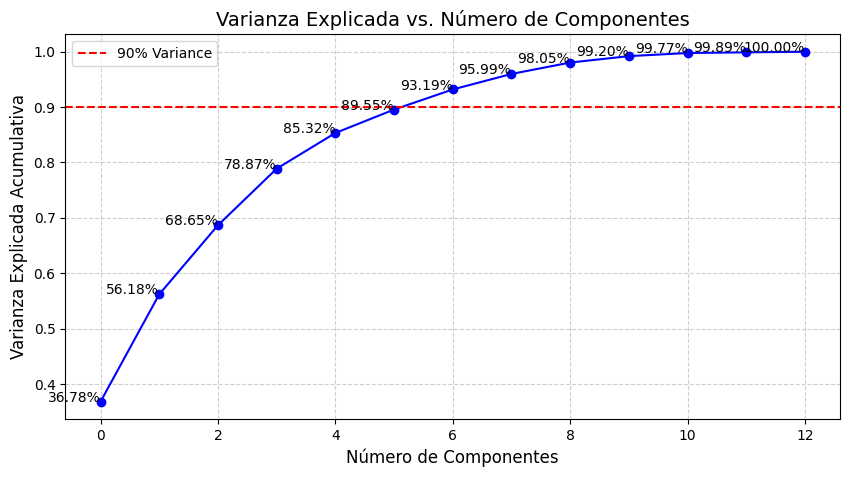

In [17]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

# Aplicar PCA conservando todas las características después de eliminar "player" y "pos"
pca = PCA(n_components=len(df_scaled.drop(columns=["player", "pos"]).columns))  # Use all features
X_pca = pca.fit_transform(df_scaled.drop(columns=["player", "pos"]))

# Gráfico de la varianza explicada acumulativa
plt.figure(figsize=(10, 5))
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o', linestyle='-', color='b')
plt.axhline(y=0.90, color='r', linestyle='dashed', label='90% Variance')

# Anotar cada punto con su porcentaje de varianza explicada
for i, var in enumerate(np.cumsum(pca.explained_variance_ratio_)):
    plt.text(i, var, f"{var:.2%}", ha="right", fontsize=10, color="black")

plt.xlabel('Número de Componentes', fontsize=12)
plt.ylabel('Varianza Explicada Acumulativa', fontsize=12)
plt.title('Varianza Explicada vs. Número de Componentes', fontsize=14)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.show()

La gráfica muestra que para conservar alrededor de un 90% de la varianza, debemos condensar los datos en 5 componentes.

In [18]:
pca = PCA(n_components=5)
X_pca = pca.fit_transform(df_scaled.drop(columns=["player", "pos"]))

In [19]:

# Convertimos a dataframe los PCA
pca_columns = [f"PC{i+1}" for i in range(X_pca.shape[1])]
df_pca = pd.DataFrame(X_pca, columns=pca_columns)
df_pca = pd.concat([df_excluir.reset_index(drop=True), df_pca], axis=1)

df_pca

,player,pos,PC1,PC2,PC3,PC4,PC5
0,Aaron Gordon,PF,1.440217,0.490980,-0.791532,0.703259,0.030581
1,Aaron Holiday,PG,-1.841278,-0.372433,0.160564,-0.583886,0.624972
2,Aaron Nesmith,SF,-0.425955,-0.258465,-1.420748,-0.977073,0.148990
3,Aaron Wiggins,SG,-0.747118,1.236980,-0.248668,-1.010054,0.750594
4,Al Horford,C,-0.451453,0.673020,-1.043298,-2.115742,1.471360
...,...,...,...,...,...,...,...
333,Zach Collins,C,-0.021823,0.569380,0.268592,1.548305,0.225830
334,Zach LaVine,SG,1.520756,-1.524793,-0.357585,0.354169,-0.060050
335,Zavier Simpson,PG,-3.172358,-0.484010,2.883803,1.131068,-1.517705
336,Ziaire Williams,SF,-2.159847,-0.607602,0.684137,0.637651,-0.276240


# 3. Clustering

La estrategia que seguiremos para agrupar jugadores será por posición, para tener una clasificación más completa y equilibrada. Primero, es importante determinar el número de clusters (o agrupaciones) óptimo para cada posición. Eso lo haremos con el Silhouette Score.

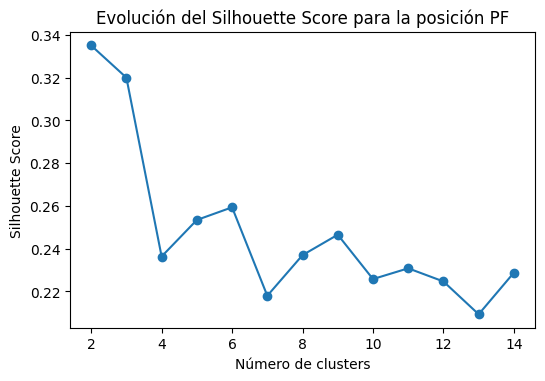

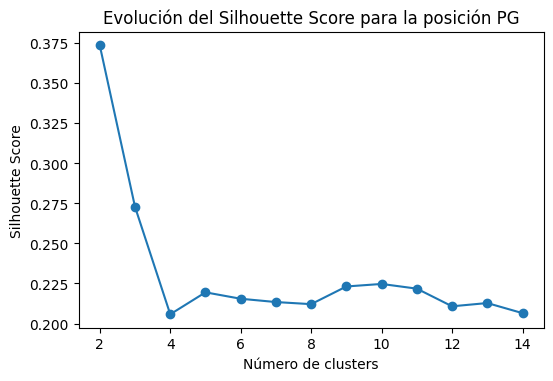

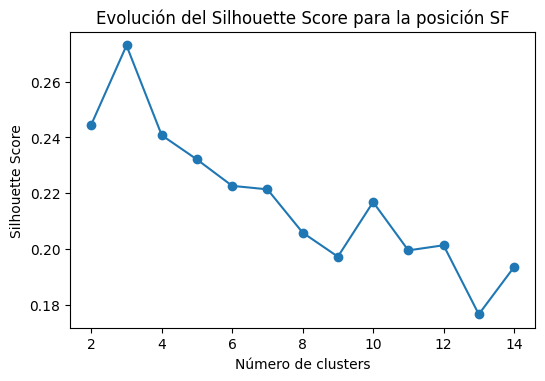

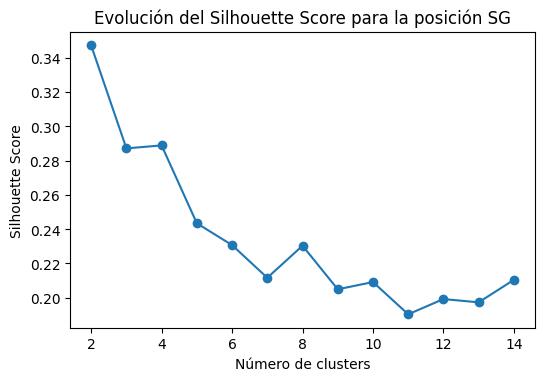

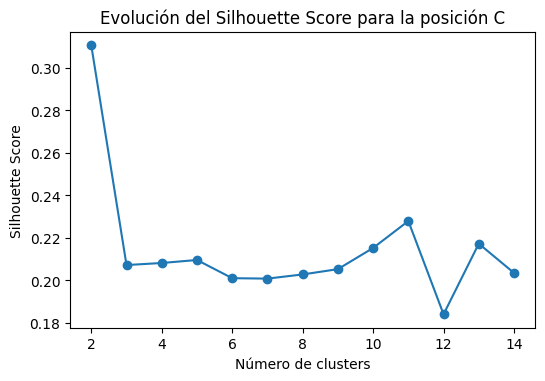

In [20]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans

# Función para encontrar el número óptimo de clusters por posición
def optimal_k_selection(df_pca):
    silhouette_scores = {}

    # Iterar por cada posición
    for pos in df_pca["pos"].unique():
        df_pos = df_pca[df_pca["pos"] == pos].drop(columns=["player", "pos"])
        # Rango de clusters a evaluar
        range_n_clusters = range(2, 15)
        silhouette_vals = []

        for n_clusters in range_n_clusters:
            kmeans = KMeans(n_clusters=n_clusters, n_init=20, random_state=123)
            cluster_labels = kmeans.fit_predict(df_pos)
            silhouette_avg = silhouette_score(df_pos, cluster_labels)
            silhouette_vals.append(silhouette_avg)

         # Seleccionar el número óptimo de clusters basado en el mayor Silhouette Score
        best_k = range_n_clusters[np.argmax(silhouette_vals)]
        silhouette_scores[pos] = best_k

        # Graficar la evaluación del Silhouette score
        plt.figure(figsize=(6, 3.84))
        plt.plot(range_n_clusters, silhouette_vals, marker='o')
        plt.title(f"Evolución del Silhouette Score para la posición {pos}")
        plt.xlabel("Número de clusters")
        plt.ylabel("Silhouette Score")
        plt.show()

    return silhouette_scores

# Obtener los mejores valores de K para cada posición
silhouette_scores = optimal_k_selection(df_pca)

Según las gráficas, para cada posición deberíamos usar 2 clusters (menos para alero, donde el Silhouette Score nos indica que 3 es el número óptimo de clusters a utilizar). No obstante, las métricas no dejan de ser indicativos que jamás podrán superar la interpretación y el conocimiento del contexto. Observando las gráficas resultantes, lo mejor es sacrificar algo de calidad en las agrupaciones y utilizar 3 clusters por posición. Se usará el algoritmo KMeans.


🔹 Clustering para la posición: PG


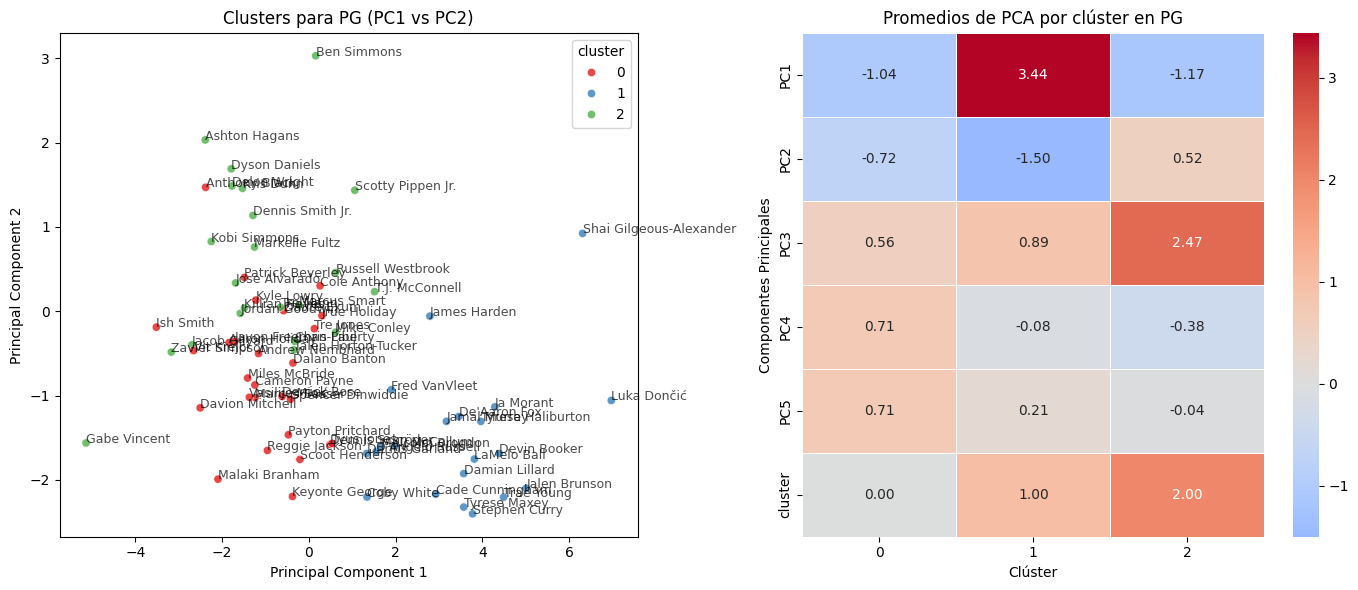


🔹 Clustering para la posición: SG


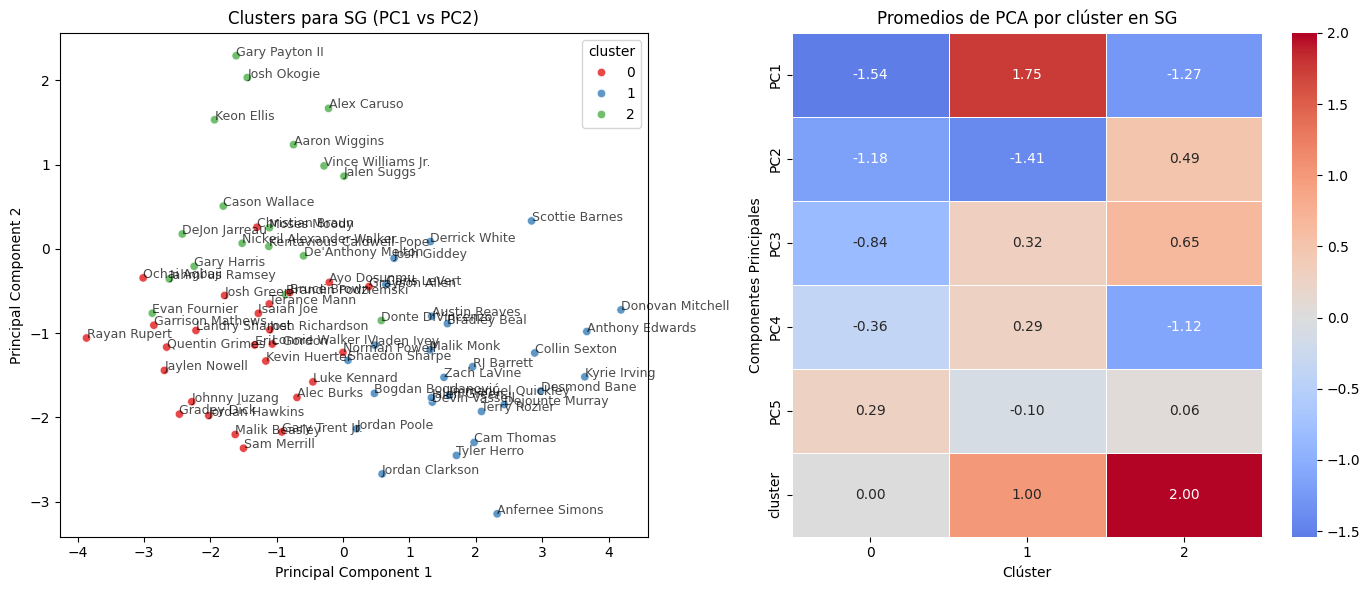


🔹 Clustering para la posición: SF


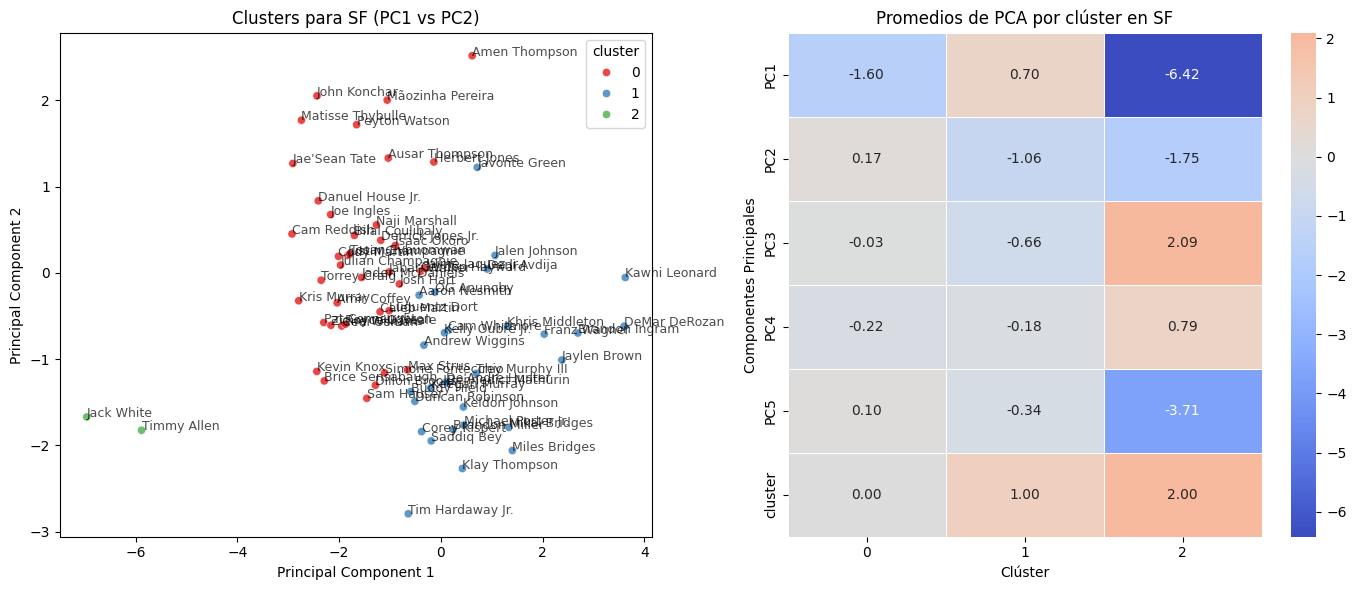


🔹 Clustering para la posición: PF


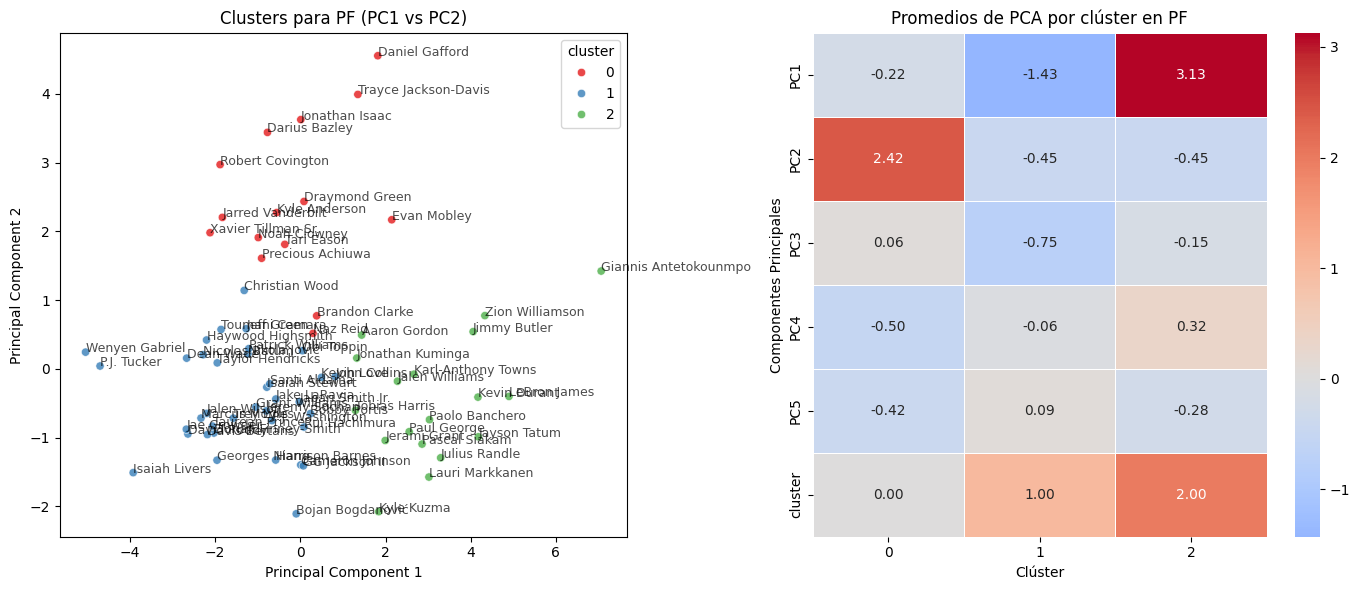


🔹 Clustering para la posición: C


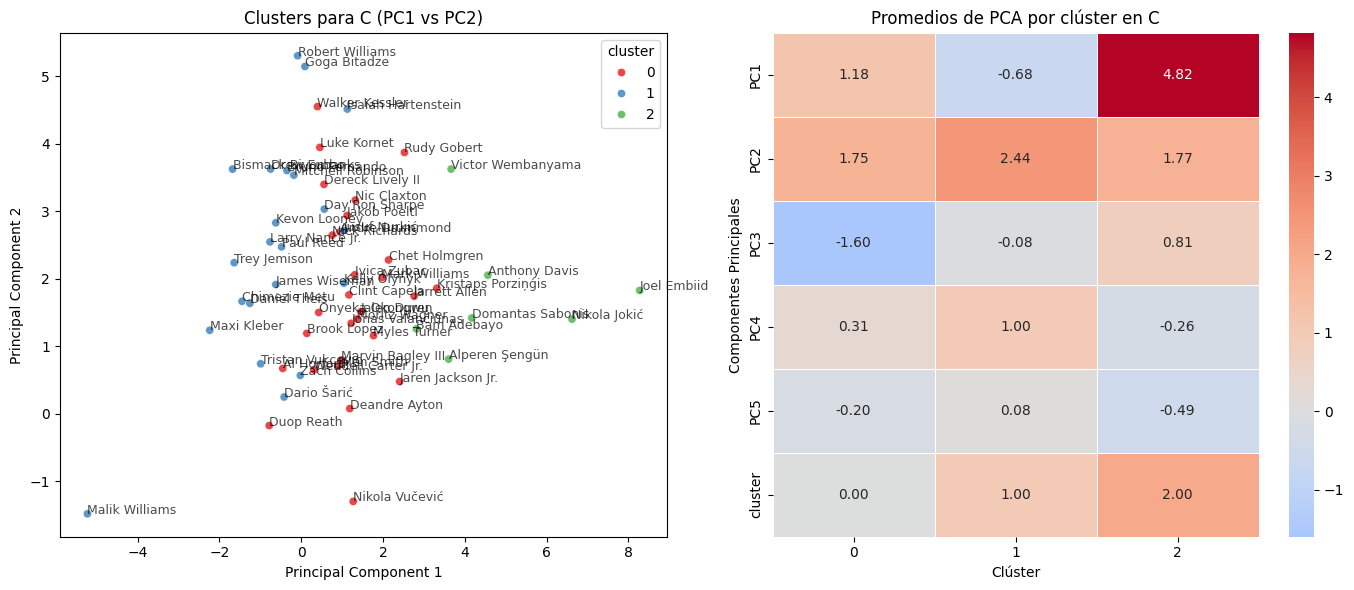

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans

# Función para aplicar K-Means y visualizar los resultados con Heatmap
def cluster_by_position(df_pca, positions):
    results = {}

    for pos in positions:
        print(f"\n🔹 Clustering para la posición: {pos}")

        df_pos = df_pca[df_pca["pos"] == pos].copy()
        X_pos = df_pos.drop(columns=["player", "pos"])

        # Aplicar K-Means con 3 clusters
        n_clusters = 3
        kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
        df_pos["cluster"] = kmeans.fit_predict(X_pos)

        fig, axes = plt.subplots(1, 2, figsize=(14, 6))  # Dos gráficos por posición

        # Scatter Plot (PC1 vs PC2)
        sns.scatterplot(
            x=df_pos["PC1"], y=df_pos["PC2"],
            hue=df_pos["cluster"], palette="Set1", alpha=0.8, ax=axes[0]
        )

        for i, player in enumerate(df_pos["player"]):
            axes[0].annotate(player, (df_pos["PC1"].iloc[i], df_pos["PC2"].iloc[i]), fontsize=9, alpha=0.7)

        axes[0].set_title(f'Clusters para {pos} (PC1 vs PC2)')
        axes[0].set_xlabel('Principal Component 1')
        axes[0].set_ylabel('Principal Component 2')

        # Heatmap con promedios por clúster
        numeric_cols = df_pos.select_dtypes(include=[np.number]).columns.tolist()  # Filtrar solo columnas numéricas
        cluster_means = df_pos.groupby("cluster")[numeric_cols].mean()

        sns.heatmap(
            cluster_means.T, cmap="coolwarm", center=0, linewidths=0.5,
            annot=True, fmt=".2f", cbar=True, ax=axes[1]
        )

        axes[1].set_title(f'Promedios de PCA por clúster en {pos}')
        axes[1].set_xlabel("Clúster")
        axes[1].set_ylabel("Componentes Principales")

        plt.tight_layout()
        plt.show()

        results[pos] = df_pos[["player", "cluster"]]

    return results

# Posiciones a analizar
positions = ['PG', 'SG', 'SF', 'PF', 'C']

# Aplicar clustering y visualizar resultados
cluster_results = cluster_by_position(df_pca, positions)


Finalmente, nos gustaría saber qué métricas tienen más impacto en cada Componente Principal para así entender mejor las agrupaciones. Para ello, utilizaremos lo que se conoce como PCA loadings.

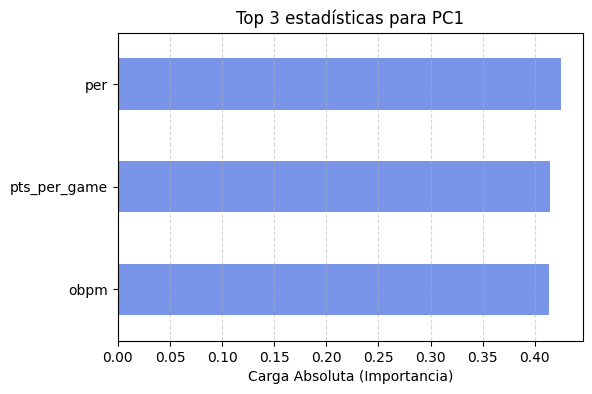

🔹 PC1 - Principales estadísticas:
per             0.424858
pts_per_game    0.414562
obpm            0.413937
Name: PC1, dtype: float64

--------------------------------------------------



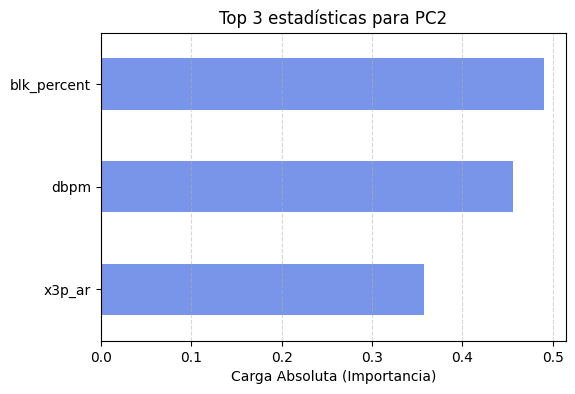

🔹 PC2 - Principales estadísticas:
blk_percent    0.489815
dbpm           0.456226
x3p_ar         0.357659
Name: PC2, dtype: float64

--------------------------------------------------



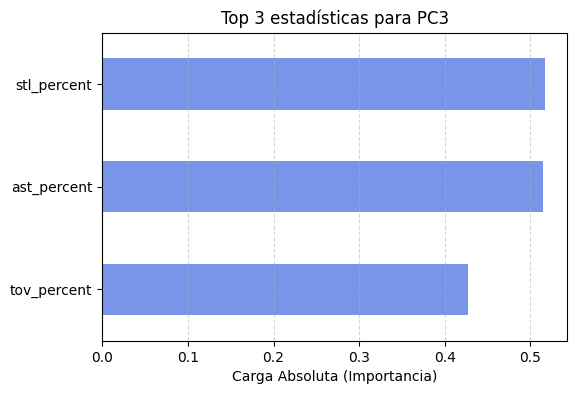

🔹 PC3 - Principales estadísticas:
stl_percent    0.517061
ast_percent    0.514361
tov_percent    0.427436
Name: PC3, dtype: float64

--------------------------------------------------



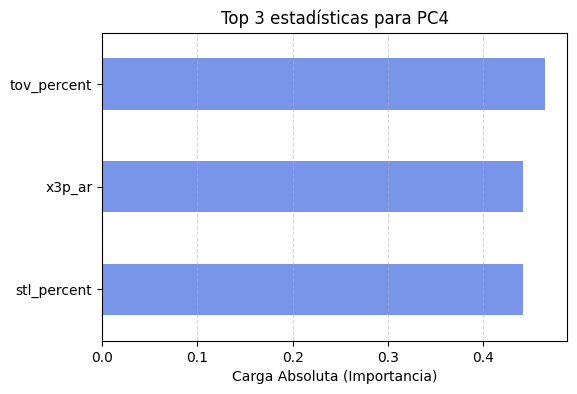

🔹 PC4 - Principales estadísticas:
tov_percent    0.465117
x3p_ar         0.441990
stl_percent    0.441673
Name: PC4, dtype: float64

--------------------------------------------------



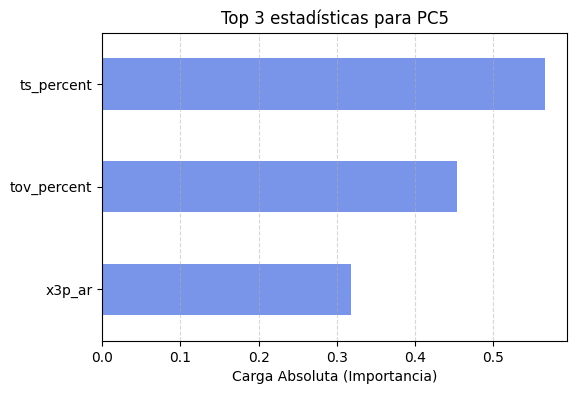

🔹 PC5 - Principales estadísticas:
ts_percent     0.566378
tov_percent    0.453373
x3p_ar         0.318601
Name: PC5, dtype: float64

--------------------------------------------------



In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

def plot_top_pca_features(pca, feature_names, top_n=3):
    """
    Muestra los top N features más influyentes en cada componente principal.
    
    Parámetros:
    - pca: objeto PCA ya entrenado.
    - feature_names: nombres de las estadísticas originales.
    - top_n: número de métricas más importantes a mostrar (por defecto, 3).
    """
    loadings = pd.DataFrame(pca.components_, columns=feature_names, index=[f"PC{i+1}" for i in range(len(pca.components_))])

    for pc in loadings.index:  # Iterar sobre PC1, PC2, PC3...
        top_features = loadings.loc[pc].abs().sort_values(ascending=False).head(top_n)
        
        # Gráfico de barras
        plt.figure(figsize=(6, 4))
        top_features[::-1].plot(kind="barh", color="royalblue", alpha=0.7)
        plt.xlabel("Carga Absoluta (Importancia)")
        plt.title(f"Top {top_n} estadísticas para {pc}")
        plt.grid(axis="x", linestyle="--", alpha=0.5)
        plt.show()

        # Mostrar en tabla también
        print(f"🔹 {pc} - Principales estadísticas:")
        print(top_features)
        print("\n" + "-"*50 + "\n")

# Llamar a la función con los datos de PCA
plot_top_pca_features(pca, df_a_normalizar.columns, top_n=3)
